Dataset Shape: (712, 12)
Number of Rows: 712
Target Variable: Survived

MODEL PERFORMANCE COMPARISON

              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression     0.818      0.767   0.793     0.780
      Decision Tree     0.818      0.808   0.724     0.764
            Bagging     0.755      0.702   0.690     0.696
      Random Forest     0.797      0.774   0.707     0.739
           AdaBoost     0.811      0.746   0.810     0.777
  Gradient Boosting     0.790      0.769   0.690     0.727
           Stacking     0.825      0.789   0.776     0.783

BEST MODEL
Model     : Stacking
Accuracy  : 0.825
Precision : 0.789
Recall    : 0.776
F1-Score  : 0.783


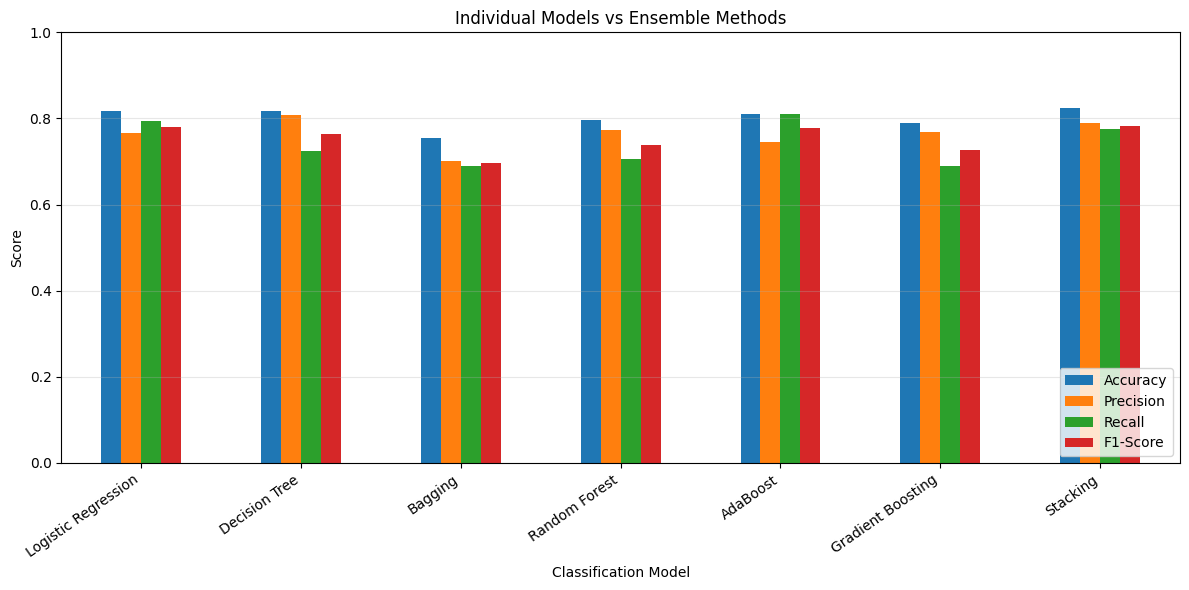

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df = df[
    ["Survived", "Pclass", "Sex", "Age", "SibSp",
     "Parch", "Fare", "Embarked"]].dropna().copy()

df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

df = pd.get_dummies(
    df, columns=["Embarked"], drop_first=True, dtype=int)

print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Target Variable: Survived")

X = df.drop("Survived", axis=1)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=5,
        random_state=42, n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, max_depth=2, random_state=42
    ),
    "Stacking": StackingClassifier(
        estimators=[
            ("lr", LogisticRegression(max_iter=1000)),
            ("dt", DecisionTreeClassifier(max_depth=5, random_state=42)),
            ("rf", RandomForestClassifier(
                n_estimators=50, max_depth=5, random_state=42, n_jobs=-1))],
        final_estimator=LogisticRegression(max_iter=1000),
        cv=5)}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    prediction = model.predict(X_test_scaled)

    results.append([
        name,
        accuracy_score(y_test, prediction),
        precision_score(y_test, prediction, zero_division=0),
        recall_score(y_test, prediction, zero_division=0),
        f1_score(y_test, prediction, zero_division=0)])

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score"])

print("\nMODEL PERFORMANCE COMPARISON\n")
print(results_df.round(3).to_string(index=False))

best = results_df.loc[results_df["F1-Score"].idxmax()]

print("\nBEST MODEL")
print("Model     :", best["Model"])
print("Accuracy  :", round(best["Accuracy"], 3))
print("Precision :", round(best["Precision"], 3))
print("Recall    :", round(best["Recall"], 3))
print("F1-Score  :", round(best["F1-Score"], 3))

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]].plot(kind="bar", figsize=(12, 6))

plt.title("Individual Models vs Ensemble Methods")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
